In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns",None)
pd.set_option("display.float_format","{:.2f}".format)
print("load thư viện")

load thư viện


In [4]:
DATA_PATH = Path("../data/house_predict.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("dataset not found")
df = pd.read_csv(DATA_PATH)
print("load data")
print(df.shape)


load data
(1460, 81)


In [5]:
display(df.head(10))

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.00,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.00,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.00,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.00,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.00,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.00,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.00,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.00,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.00,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.00,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.00,14115,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Mitchel,Norm,Norm,1Fam,1.5Fin,5,5,1993,1995,Gable,CompShg,VinylSd,VinylSd,NaN,0.00,TA,TA,Wood,Gd,TA,No,GLQ,732,Unf,0,64,796,GasA,Ex,Y,SBrkr,796,566,0,1362,1,0,1,1,1,1,TA,5,Typ,0,NaN,Attchd,1993.00,Unf,2,480,TA,TA,Y,40,30,0,320,0,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.00,10084,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Somerst,Norm,Norm,1Fam,1Story,8,5,2004,2005,Gable,CompShg,VinylSd,VinylSd,Stone,186.00,Gd,TA,PConc,Ex,TA,Av,GLQ,1369,Unf,0,317,1686,GasA,Ex,Y,SBrkr,1694,0,0,1694,1,0,2,0,3,1,Gd,7,Typ,1,Gd,Attchd,2004.00,RFn,2,636,TA,TA,Y,255,57,0,0,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NWAmes,PosN,Norm,1Fam,2Story,7,6,1973,1973,Gable,CompShg,HdBoard,HdBoard,Stone,240.00,TA,TA,CBlock,Gd,TA,Mn,ALQ,859,BLQ,32,216,1107,GasA,Ex,Y,SBrkr,1107,983,0,2090,1,0,2,1,3,1,TA,7,Typ,2,TA,Attchd,1973.00,RFn,2,484,TA,TA,Y,235,204,228,0,0,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.00,6120,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,OldTown,Artery,Norm,1Fam,1.5Fin,7,5,1931,1950,Gable,CompShg,BrkFace,Wd Shng,NaN,0.00,TA,TA,BrkTil,TA,TA,No,Unf,0,Unf,0,952,952,GasA,Gd,Y,FuseF,1022,752,0,1774,0,0,2,0,2,2,TA,8,Min1,2,TA,Detchd,1931.00,Unf,2,468,Fa,TA,Y,90,0,205,0,0,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.00,7420,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,BrkSide,Artery,Artery,2fmCon,1.5Unf,5,6,1939,1950,Gable,CompShg,MetalSd,MetalSd,NaN,0.00,TA,TA,BrkTil,TA,TA,No,GL

In [6]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,1460.00,NaN,NaN,NaN,730.50,421.61,1.00,365.75,730.50,1095.25,1460.00
MSSubClass,1460.00,NaN,NaN,NaN,56.90,42.30,20.00,20.00,50.00,70.00,190.00
MSZoning,1460,5,RL,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,1201.00,NaN,NaN,NaN,70.05,24.28,21.00,59.00,69.00,80.00,313.00
LotArea,1460.00,NaN,NaN,NaN,10516.83,9981.26,1300.00,7553.50,9478.50,11601.50,215245.00
...,...,...,...,...,...,...,...,...,...,...,...
MoSold,1460.00,NaN,NaN,NaN,6.32,2.70,1.00,5.00,6.00,8.00,12.00
YrSold,1460.00,NaN,NaN,NaN,2007.82,1.33,2006.00,2007.00,2008.00,2009.00,2010.00
SaleType,1460,9,WD,1267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SaleCondition,1460,6,Normal,1198,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
missing = pd.DataFrame({
    "missing_count":df.isnull().sum(),
    "missing_percent":df.isnull().mean()*100
})
missing = missing.sort_values(
    by = "missing_percent",
    ascending = False
)
display(missing[missing["missing_count"] > 0])

,missing_count,missing_percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageQual,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55


In [10]:
print(df.duplicated().sum())
print(df["Id"].nunique())
print(len(df))

0
1460
1460


In [11]:
numerical_features = df.select_dtypes(include = ["int64","float64"]).columns.tolist()
categorical_features = df.select_dtypes(include = ["object"]).columns.tolist()
print(len(numerical_features))
print(len(categorical_features))
print(numerical_features)
print(categorical_features)

38
43
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish',

C:\Users\PC\AppData\Local\Temp\ipykernel_34048\2249466967.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include = ["object"]).columns.tolist()


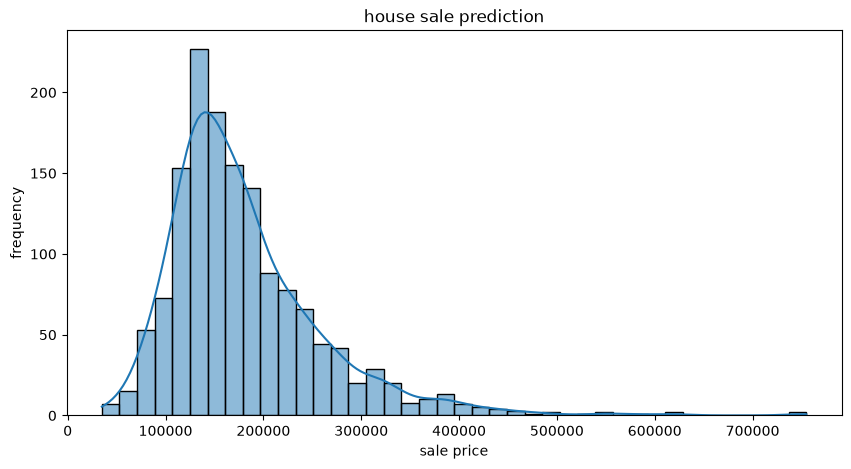

In [12]:
plt.figure(figsize = (10,5)) # tạo biểu đồ kích thước 10x5 inch
sns.histplot(df["SalePrice"],bins=40,kde=True) #Vẽ Histogram – biểu đồ tần suất phân phối dữ liệu.chia giá 40 nhóm, vẽ đường kde
plt.title("house sale prediction")
plt.xlabel("sale price")
plt.ylabel("frequency")
plt.show() #hiển thị biểu đồ

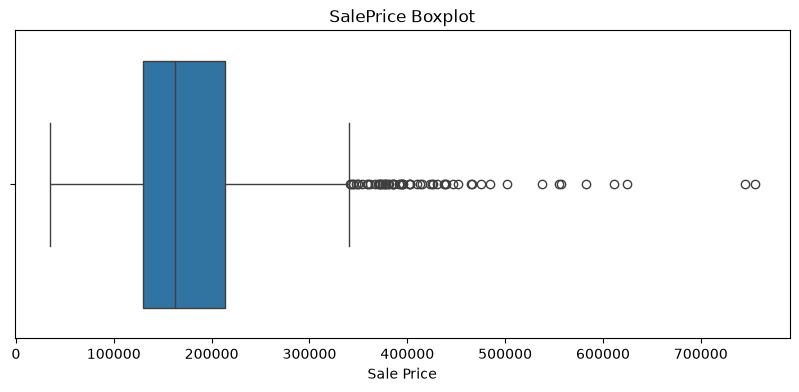

In [13]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df["SalePrice"])
plt.title("SalePrice Boxplot")
plt.xlabel("Sale Price")
plt.show()

In [14]:
Q1 = df["SalePrice"].quantile(0.25)
Q3 = df["SalePrice"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["SalePrice"] < lower_bound) |
    (df["SalePrice"] > upper_bound)
]

print(f"Q1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Lower bound: {lower_bound}")
print(f"Upper bound: {upper_bound}")
print(f"Outlier count: {len(outliers)}")
print(f"Outlier percentage: {len(outliers) / len(df) * 100:.2f}%")

Q1: 129975.0
Q3: 214000.0
IQR: 84025.0
Lower bound: 3937.5
Upper bound: 340037.5
Outlier count: 61
Outlier percentage: 4.18%


In [15]:
correlation = (
    df.select_dtypes(include=["int64","float64"]).corr()["SalePrice"].sort_values(ascending=False))
display(correlation)

# select_dtypes(): chỉ lấy các cột số.
# .corr(): tính hệ số tương quan Pearson giữa các cột.
# ["SalePrice"]: chỉ lấy tương quan với giá nhà.
# sort_values(): sắp xếp từ cao xuống thấp.

SalePrice        1.00
OverallQual      0.79
GrLivArea        0.71
GarageCars       0.64
GarageArea       0.62
TotalBsmtSF      0.61
1stFlrSF         0.61
FullBath         0.56
TotRmsAbvGrd     0.53
YearBuilt        0.52
YearRemodAdd     0.51
GarageYrBlt      0.49
MasVnrArea       0.48
Fireplaces       0.47
BsmtFinSF1       0.39
LotFrontage      0.35
WoodDeckSF       0.32
2ndFlrSF         0.32
OpenPorchSF      0.32
HalfBath         0.28
LotArea          0.26
BsmtFullBath     0.23
BsmtUnfSF        0.21
BedroomAbvGr     0.17
ScreenPorch      0.11
PoolArea         0.09
MoSold           0.05
3SsnPorch        0.04
BsmtFinSF2      -0.01
BsmtHalfBath    -0.02
MiscVal         -0.02
Id              -0.02
LowQualFinSF    -0.03
YrSold          -0.03
OverallCond     -0.08
MSSubClass      -0.08
EnclosedPorch   -0.13
KitchenAbvGr    -0.14
Name: SalePrice, dtype: float64

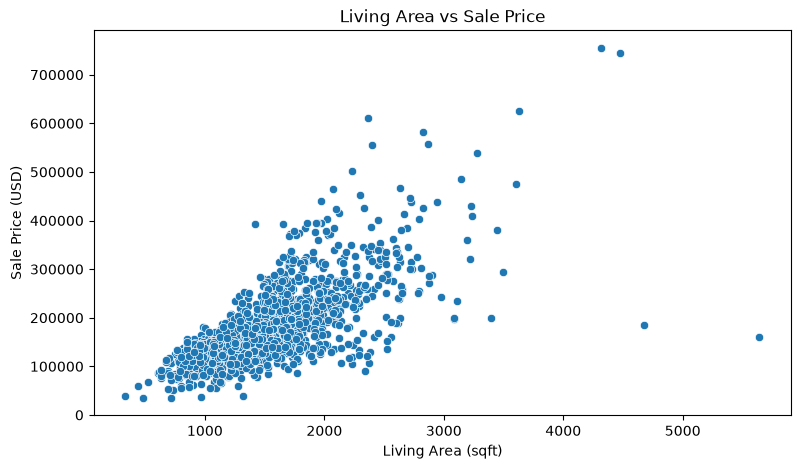

In [16]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Living Area (sqft)")
plt.ylabel("Sale Price (USD)")

plt.show()
# Giải thích cell
# - scatterplot(): biểu đồ phân tán, mỗi chấm đại diện cho một căn nhà.
# - Trục X: diện tích sinh hoạt.
# - Trục Y: giá bán.
# - Mỗi điểm dữ liệu giúp ta quan sát mối quan hệ giữa hai biến

In [17]:
suspicious_houses = df[
    (df["GrLivArea"] > 4000) &
    (df["SalePrice"] < 300000)
]

display(
    suspicious_houses[
        ["Id", "GrLivArea", "OverallQual", "YearBuilt", "SalePrice"]
    ]
)
# df["GrLivArea"] > 4000: lọc nhà có diện tích trên 4.000 sqft.
# df["SalePrice"] < 300000: lọc nhà có giá dưới 300.000 USD.
# &: kết hợp hai điều kiện AND.
# df[...]: lấy những dòng thỏa mãn cả hai điều kiện.

,Id,GrLivArea,OverallQual,YearBuilt,SalePrice
523,524,4676,10,2007,184750
1298,1299,5642,10,2008,160000


In [19]:
display(
    df.loc[
        suspicious_houses.index
    ].T
)
# suspicious_houses.index: lấy index của hai bản ghi đã phát hiện.
# df.loc[...]: truy xuất toàn bộ thông tin của hai căn nhà trong dataset.
# .T: Transpose, chuyển hàng thành cột để dễ quan sát 80 đặc trưng.

,523,1298
Id,524,1299
MSSubClass,60,60
MSZoning,RL,RL
LotFrontage,130.00,313.00
LotArea,40094,63887
...,...,...
MoSold,10,1
YrSold,2007,2008
SaleType,New,New
SaleCondition,Partial,Partial


In [20]:
investigation_features = [
    "Id",
    "Neighborhood",
    "OverallQual",
    "OverallCond",
    "GrLivArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "GarageCars",
    "GarageArea",
    "YearBuilt",
    "YearRemodAdd",
    "SaleType",
    "SaleCondition",
    "SalePrice"
]

display(
    df.loc[
        suspicious_houses.index,
        investigation_features
    ].T
)
# Cell này có giá trị gì?
# Chúng ta đang kiểm tra xem giá thấp có thể được giải thích bởi các yếu tố khác hay không:
# - Neighborhood: vị trí căn nhà.
# - TotalBsmtSF: diện tích tầng hầm.
# - GarageCars, GarageArea: khả năng và diện tích garage.
# - OverallCond: tình trạng hiện tại của căn nhà.
# - SaleCondition: điều kiện giao dịch.
# Một kiến thức cần ghi nhớ
# Data Anomaly ≠ Data Error
# - Data Anomaly: dữ liệu khác biệt so với phần lớn mẫu.
# - Data Error: dữ liệu sai do nhập liệu, thu thập hoặc xử lý.
# - Valid Outlier: giá trị cực đoan nhưng vẫn hợp lệ.

,523,1298
Id,524,1299
Neighborhood,Edwards,Edwards
OverallQual,10,10
OverallCond,5,5
GrLivArea,4676,5642
TotalBsmtSF,3138,6110
1stFlrSF,3138,4692
2ndFlrSF,1538,950
GarageCars,3,2
GarageArea,884,1418
